# 第 2 章 懂点概率论 —— 代码实验

对应笔记 `docs/mc/ch02.md`。六个实验：两骰子和的分布、贝叶斯检测、指数分布与样本统计量（无偏性）、联合分布与“相关 ≠ 独立”、随机变量变换、大数定律与中心极限定理。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False

FIGDIR = Path(r"E:/Desktop/深度学习/mynotes/docs/mc/images/ch02")
FIGDIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIGDIR / name, dpi=150, bbox_inches="tight")

rng = np.random.default_rng(2025)

## 2.2 直观概率：两颗骰子的和

两颗均匀骰子之和 $S\in\{2,\dots,12\}$：模拟频率 vs 理论概率（卷积）。

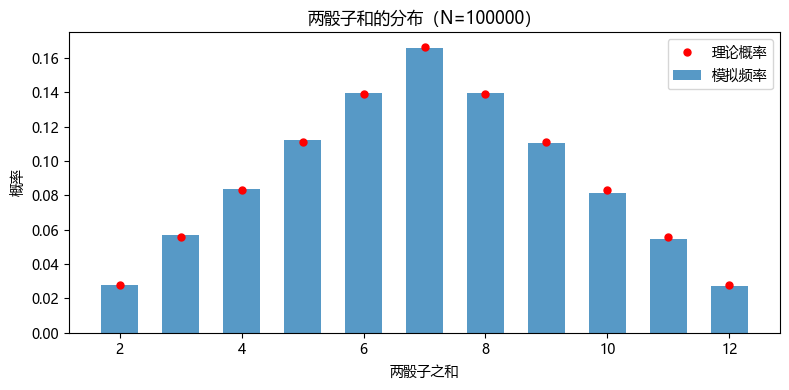

最大偏差: 0.001983333333333323


In [2]:
N = 100_000
s = rng.integers(1, 7, N) + rng.integers(1, 7, N)
vals, cnts = np.unique(s, return_counts=True)
freq = cnts / N
p_die = np.ones(6) / 6
theory = np.convolve(p_die, p_die)   # 和的分布 = 分布的卷积

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(vals, freq, width=0.6, alpha=0.75, label="模拟频率")
ax.plot(range(2, 13), theory, "ro", ms=5, label="理论概率")
ax.set(xlabel="两骰子之和", ylabel="概率", title=f"两骰子和的分布（N={N}）")
ax.legend()
fig.tight_layout(); save(fig, "out-dice.png"); plt.show()

print("最大偏差:", np.abs(freq - theory).max())

## 2.2 条件概率与贝叶斯：疾病检测

患病率 1%、灵敏度 99%、特异度 95%。检测阳性的人里真病人占多少？用 100 万人直接数。

阳性人群中：真病人 10071 人，假阳性 49450 人 -> P(患病|阳性) = 0.1692
贝叶斯公式：0.0099/(0.0099+0.0495) = 0.1667


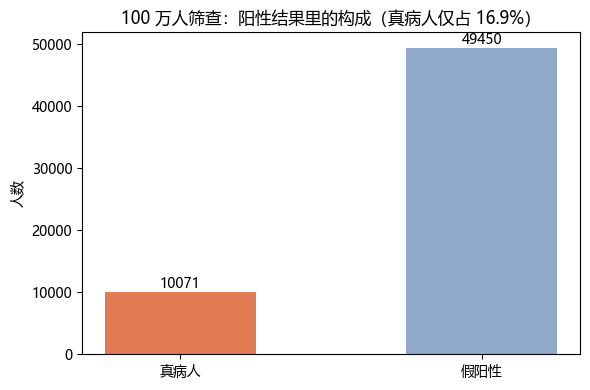

In [3]:
Pop = 1_000_000
prev, sens, spec = 0.01, 0.99, 0.95
sick = rng.random(Pop) < prev                                   # 是否真患病
pos = np.where(sick, rng.random(Pop) < sens, rng.random(Pop) < 1 - spec)

tp, fp = int((sick & pos).sum()), int((~sick & pos).sum())      # 真阳性 / 假阳性
ppv = tp / (tp + fp)
print(f"阳性人群中：真病人 {tp} 人，假阳性 {fp} 人 -> P(患病|阳性) = {ppv:.4f}")
print(f"贝叶斯公式：{prev*sens:.4f}/({prev*sens:.4f}+{0.99*0.05:.4f}) = {prev*sens/(prev*sens+(1-prev)*(1-spec)):.4f}")

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["真病人", "假阳性"], [tp, fp], width=0.5, color=["#e07b54", "#8ea9c9"])
ax.bar_label(bars, fmt="%d")
ax.set(ylabel="人数", title=f"100 万人筛查：阳性结果里的构成（真病人仅占 {ppv*100:.1f}%）")
fig.tight_layout(); save(fig, "out-bayes.png"); plt.show()

## 2.3/2.4 指数分布：直方图 vs 密度，样本统计量 vs 总体矩

均值 $\mu=2$ 的指数分布（如何从均匀随机数造出它，第 5 章逆变换法揭晓）。顺便验证：$\bar x\to\mu$，$s^2\to\sigma^2$，以及 $\mathbb E[s^2]=\sigma^2$（除 $n-1$ 的无偏性）。

样本均值 = 1.9889（总体 2），样本方差(ddof=1) = 3.9410（总体 4）
E[s²(n-1)] = 3.9703 ≈ σ²=4 ；E[s²(n)] = 3.5749 ≈ σ²(n-1)/n = 3.6


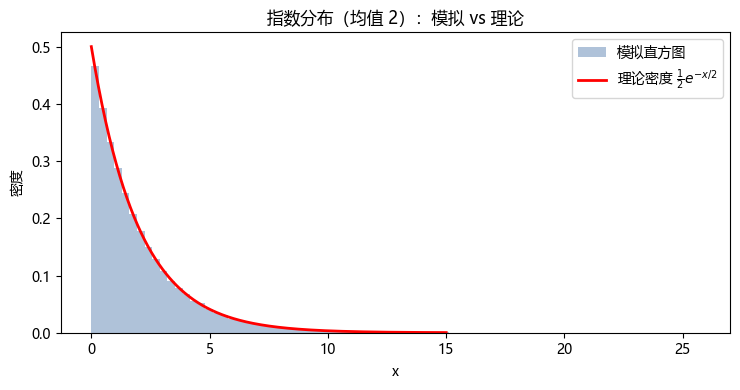

In [4]:
X = rng.exponential(2.0, 200_000)
print(f"样本均值 = {X.mean():.4f}（总体 2），样本方差(ddof=1) = {X.var(ddof=1):.4f}（总体 4）")

reps, n = 20_000, 10
s2 = rng.exponential(2.0, (reps, n)).var(axis=1, ddof=1)   # 每组 n=10 算 s²
s2n = rng.exponential(2.0, (reps, n)).var(axis=1, ddof=0)  # 除 n 的版本
print(f"E[s²(n-1)] = {s2.mean():.4f} ≈ σ²=4 ；E[s²(n)] = {s2n.mean():.4f} ≈ σ²(n-1)/n = 3.6")

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.hist(X, bins=80, density=True, alpha=0.7, color="#8ea9c9", label="模拟直方图")
xg = np.linspace(0, 15, 400)
ax.plot(xg, np.exp(-xg/2)/2, "r-", lw=2, label=r"理论密度 $\frac{1}{2}e^{-x/2}$")
ax.set(xlabel="x", ylabel="密度", title="指数分布（均值 2）：模拟 vs 理论")
ax.legend()
fig.tight_layout(); save(fig, "out-exp.png"); plt.show()

## 2.4 联合分布：二维正态 与 “相关 = 0 但不独立”

左：二维正态（ρ=0.6）。右：$Z=X^2$ 与 $X$ 的相关系数为 0，但显然不独立——相关系数只量线性关系。

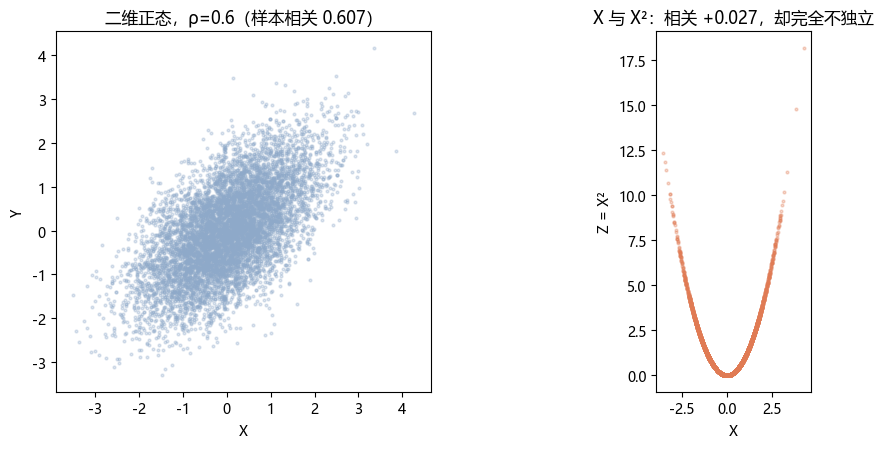

In [5]:
n = 8000
rho = 0.6
X = rng.normal(0, 1, n)
Y = rho * X + np.sqrt(1 - rho**2) * rng.normal(0, 1, n)
Z = X**2

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
axes[0].scatter(X, Y, s=4, alpha=0.3, color="#8ea9c9")
axes[0].set(title=f"二维正态，ρ={rho}（样本相关 {np.corrcoef(X, Y)[0,1]:.3f}）",
            xlabel="X", ylabel="Y", aspect="equal")
axes[1].scatter(X, Z, s=4, alpha=0.3, color="#e07b54")
axes[1].set(title=f"X 与 X²：相关 {np.corrcoef(X, Z)[0,1]:+.3f}，却完全不独立",
            xlabel="X", ylabel="Z = X²", aspect="equal")
fig.tight_layout(); save(fig, "out-joint.png"); plt.show()

## 2.5 随机变量的变换：$Y=U^2$ 的密度

$U\sim U(0,1)$，$Y=U^2$。CDF 法：$F_Y(y)=P(U\le\sqrt y)=\sqrt y$，故 $f_Y(y)=\frac{1}{2\sqrt y}$，$y\in(0,1]$。直方图验证。

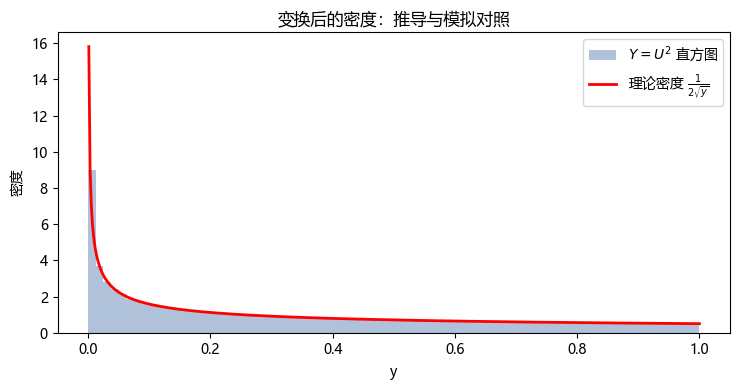

In [6]:
U = rng.random(200_000)
Y = U**2

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.hist(Y, bins=80, density=True, alpha=0.7, color="#8ea9c9", label="$Y=U^2$ 直方图")
yg = np.linspace(0.001, 1, 500)
ax.plot(yg, 1/(2*np.sqrt(yg)), "r-", lw=2, label=r"理论密度 $\frac{1}{2\sqrt{y}}$")
ax.set(xlabel="y", ylabel="密度", title="变换后的密度：推导与模拟对照")
ax.legend()
fig.tight_layout(); save(fig, "out-transform.png"); plt.show()

## 2.6 大数定律与中心极限定理

上：8 条抛硬币频率轨迹（对数横轴），±0.01 阴影带；切比雪夫不等式保证 $P(|\hat p - 0.5|\ge 0.01)\le \frac{0.25}{N\cdot 0.01^2}$。

下：$\mathrm{Exp}(1)$ 样本和的标准化 $Z=\frac{S_n-n}{\sqrt n}$，$n=1,5,30,200$——不管原来多偏，和的分布滑向标准正态。

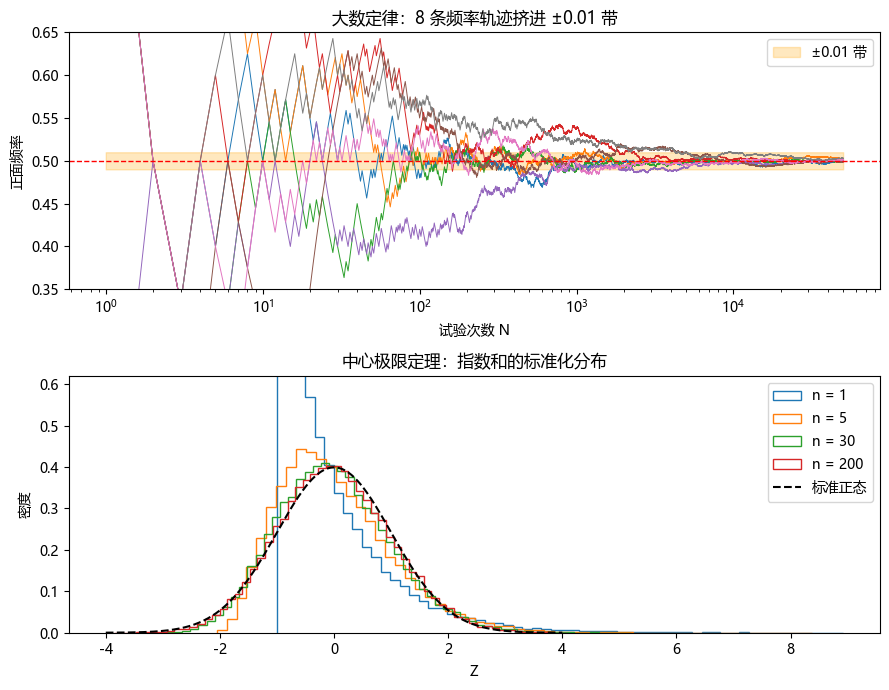

n=  1: 偏度 = +2.093（标准正态为 0）
n=  5: 偏度 = +0.857（标准正态为 0）
n= 30: 偏度 = +0.383（标准正态为 0）
n=200: 偏度 = +0.135（标准正态为 0）


In [7]:
N, npaths = 50_000, 8
flips = rng.random((npaths, N)) < 0.5
freq = flips.cumsum(axis=1) / np.arange(1, N + 1)

fig, axes = plt.subplots(2, 1, figsize=(9, 7))
ns = np.arange(1, N + 1)
axes[0].fill_between(ns, 0.49, 0.51, color="orange", alpha=0.25, label="±0.01 带")
for p in freq:
    axes[0].plot(ns, p, lw=0.7)
axes[0].axhline(0.5, color="r", ls="--", lw=1)
axes[0].set_xscale("log"); axes[0].set_ylim(0.35, 0.65)
axes[0].set(title="大数定律：8 条频率轨迹挤进 ±0.01 带", xlabel="试验次数 N", ylabel="正面频率")
axes[0].legend(loc="upper right")

reps = 50_000
for k, n in enumerate([1, 5, 30, 200]):
    S = rng.exponential(1.0, (reps, n)).sum(axis=1)
    Z = (S - n) / np.sqrt(n)          # Exp(1) 的 μ=σ²=1
    axes[1].hist(Z, bins=60, density=True, histtype="step",
                 lw=1.5, label=f"n = {n}", color=f"C{k}")
xg = np.linspace(-4, 4, 300)
axes[1].plot(xg, np.exp(-xg**2/2)/np.sqrt(2*np.pi), "k--", lw=1.5, label="标准正态")
axes[1].set(title="中心极限定理：指数和的标准化分布", xlabel="Z", ylabel="密度", ylim=(0, 0.62))
axes[1].legend()
fig.tight_layout(); save(fig, "out-lln-clt.png"); plt.show()

for n in [1, 5, 30, 200]:
    S = rng.exponential(1.0, (reps, n)).sum(axis=1)
    Z = (S - n) / np.sqrt(n)
    print(f"n={n:>3}: 偏度 = {float(((Z - Z.mean())**3).mean()):+.3f}（标准正态为 0）")